# UrbanMove — Patrones Invisibles: Información, Incertidumbre y Movilidad Urbana

Notebook editable con el pipeline completo de `analisis_urbanmove.py`, ejecutado sobre el **dataset real de Kaggle** (`train.csv` — NYC Taxi Trip Duration), no la demo sintética.

**Antes de correr:** coloca `train.csv` en la misma carpeta que este notebook (o cambia `DATA_PATH` en la celda de configuración).

Estructura:
- **Sección 0** — Configuración y carga de datos
- **Sección 1 (Rol 1)** — Incertidumbre e información (entropía, KL, información mutua, log-sum-exp)
- **Sección 2 (Rol 2)** — Segmentación por partición (K-Means, DBSCAN)
- **Sección 3 (Rol 3)** — Mezclas gaussianas y variables latentes (GMM)
- **Sección 4 (Rol 4)** — Insumos cuantitativos para recomendaciones de negocio
- **Resumen final** — Todos los resultados listos para copiar al documento/diapositivas


## 0. Configuración y carga de datos

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import entropy as scipy_entropy
from scipy.special import logsumexp
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# =============================================================================
# CONFIGURACIÓN — datos reales de Kaggle
# =============================================================================
USE_SYNTHETIC_DEMO = False   # ya tenemos el dataset real, no se usa la demo
DATA_PATH = "train.csv"      # cambia esta ruta si el archivo está en otra carpeta
SAMPLE_SIZE = 40000          # tamaño de muestra sugerido y justificable (30k-50k)


In [2]:
def cargar_datos_reales(path, n=SAMPLE_SIZE):
    df = pd.read_csv(path)
    df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
    if len(df) > n:
        df = df.sample(n=n, random_state=RANDOM_STATE).reset_index(drop=True)
    return df


def generar_datos_sinteticos_demo(n=SAMPLE_SIZE):
    """
    Genera una muestra SINTÉTICA ilustrativa, no el dataset real.
    Se deja disponible solo como referencia / respaldo si el archivo real no está disponible.
    """
    zonas = {
        "Manhattan-Centro": (40.758, -73.985, 0.01),
        "Manhattan-Alto":   (40.812, -73.955, 0.01),
        "Manhattan-Bajo":   (40.708, -74.010, 0.008),
        "JFK-Airport":      (40.641, -73.778, 0.006),
        "LGA-Airport":      (40.777, -73.874, 0.006),
    }
    zona_probs_hora_pico = [0.40, 0.20, 0.15, 0.15, 0.10]
    zona_probs_valle     = [0.30, 0.25, 0.25, 0.10, 0.10]

    rng = np.random.default_rng(RANDOM_STATE)
    fechas_base = pd.date_range("2016-03-01", "2016-06-30", freq="min")

    rows = []
    zona_names = list(zonas.keys())
    for _ in range(n):
        hora = rng.choice(range(24), p=_perfil_horario())
        es_pico = hora in (7, 8, 17, 18)
        probs = zona_probs_hora_pico if es_pico else zona_probs_valle
        zona = rng.choice(zona_names, p=probs)
        lat0, lon0, jitter = zonas[zona]
        pu_lat = lat0 + rng.normal(0, jitter)
        pu_lon = lon0 + rng.normal(0, jitter)

        if zona in ("JFK-Airport", "LGA-Airport"):
            perfil = 1
        elif hora in (22, 23, 0, 1, 2, 3):
            perfil = 2
        else:
            perfil = rng.choice([0, 1, 2], p=[0.7, 0.15, 0.15])

        if perfil == 0:
            dur = rng.normal(600, 180)
            dist_km = rng.normal(2.5, 1.0)
        elif perfil == 1:
            dur = rng.normal(2400, 500)
            dist_km = rng.normal(22, 5)
        else:
            dur = rng.normal(1100, 350)
            dist_km = rng.normal(6, 2.5)

        dur = max(60, dur)
        dist_km = max(0.3, dist_km)
        ang = rng.uniform(0, 2 * np.pi)
        do_lat = pu_lat + (dist_km / 111) * np.cos(ang)
        do_lon = pu_lon + (dist_km / (111 * np.cos(np.radians(pu_lat)))) * np.sin(ang)

        fecha = fechas_base[rng.integers(0, len(fechas_base))]
        fecha = fecha.replace(hour=hora, minute=int(rng.integers(0, 60)))

        rows.append({
            "pickup_datetime": fecha,
            "pickup_latitude": pu_lat, "pickup_longitude": pu_lon,
            "dropoff_latitude": do_lat, "dropoff_longitude": do_lon,
            "passenger_count": rng.choice([1, 1, 1, 2, 2, 3, 4], 1)[0],
            "vendor_id": rng.choice([1, 2]),
            "trip_duration": dur,
            "zona_real_demo": zona,
            "perfil_real_demo": perfil,
        })
    return pd.DataFrame(rows)


def _perfil_horario():
    base = np.array([1,1,1,1,1,2,4,8,9,5,4,4,5,5,5,5,6,9,8,5,4,3,2,1], dtype=float)
    return base / base.sum()


In [3]:
if USE_SYNTHETIC_DEMO:
    print(">>> MODO DEMO: usando muestra sintética ilustrativa (NO datos reales de Kaggle)\n")
    df = generar_datos_sinteticos_demo(SAMPLE_SIZE)
else:
    print(">>> Cargando muestra real desde", DATA_PATH)
    df = cargar_datos_reales(DATA_PATH, SAMPLE_SIZE)

df.head()


>>> Cargando muestra real desde train.csv


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2793718,2,2016-06-08 07:36:19,2016-06-08 07:53:39,1,-73.985611,40.735943,-73.980331,40.760468,N,1040
1,id3485529,2,2016-04-03 12:58:11,2016-04-03 13:11:58,1,-73.978394,40.764351,-73.991623,40.749859,N,827
2,id1816614,2,2016-06-05 02:49:13,2016-06-05 02:59:27,5,-73.989059,40.744389,-73.973381,40.748692,N,614
3,id1050851,2,2016-05-05 17:18:27,2016-05-05 17:32:54,2,-73.990326,40.731136,-73.991264,40.748917,N,867
4,id0140657,1,2016-05-12 17:43:38,2016-05-12 19:06:25,4,-73.789497,40.646675,-73.987137,40.759232,N,4967


### Variables derivadas (comunes a todos los roles)

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distancia_km"] = haversine_km(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)
df["hora"] = df["pickup_datetime"].dt.hour
df["dia_semana"] = df["pickup_datetime"].dt.dayofweek  # 0=lunes
df["es_fin_de_semana"] = df["dia_semana"].isin([5, 6])
df["velocidad_kmh"] = (df["distancia_km"] / (df["trip_duration"] / 3600)).replace(
    [np.inf, -np.inf], np.nan
)
# filtro básico de outliers evidentes (velocidad imposible, duración absurda)
df = df[(df["velocidad_kmh"] > 1) & (df["velocidad_kmh"] < 120)]
df = df[(df["trip_duration"] > 30) & (df["trip_duration"] < 3 * 3600)]

print(f"Muestra final tras limpieza: {len(df)} viajes")
df.describe()


Muestra final tras limpieza: 39540 viajes


,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,distancia_km,hora,dia_semana,velocidad_kmh
count,39540.000000,39540,39540.000000,39540.000000,39540.000000,39540.000000,39540.000000,39540.000000,39540.000000,39540.000000,39540.000000,39540.000000
mean,1.534674,2016-04-01 08:33:30.527997,1.670207,-73.973534,40.751048,-73.973482,40.751785,842.563404,3.465730,13.589681,3.059004,14.457823
min,1.000000,2016-01-01 00:08:09,1.000000,-74.103378,40.398251,-74.711327,40.483170,31.000000,0.009354,0.000000,0.000000,1.004336
25%,1.000000,2016-02-17 15:25:22.750000,1.000000,-73.991966,40.737526,-73.991259,40.735879,400.000000,1.254820,9.000000,1.000000,9.177082
50%,2.000000,2016-04-01 15:43:14,1.000000,-73.981678,40.754189,-73.979782,40.754482,664.000000,2.105616,14.000000,3.000000,12.806081
75%,2.000000,2016-05-14 23:14:34,2.000000,-73.967299,40.768360,-73.962858,40.769776,1081.000000,3.905487,19.000000,5.000000,17.929382
max,2.000000,2016-06-30 23:50:03,6.000000,-73.774757,40.896198,-73.516922,41.149899,9155.000000,61.648461,23.000000,6.000000,81.713718
std,0.498803,NaN,1.314862,0.037570,0.027688,0.035411,0.032235,657.324587,3.925547,6.389281,1.953527,7.641772


In [5]:
# Zona de recogida vía grid geográfico simple (para Rol 1 y como referencia de Rol 2)
N_BINS = 6
df["zona_lat_bin"] = pd.cut(df["pickup_latitude"], bins=N_BINS, labels=False)
df["zona_lon_bin"] = pd.cut(df["pickup_longitude"], bins=N_BINS, labels=False)
df["zona_grid"] = df["zona_lat_bin"].astype(str) + "_" + df["zona_lon_bin"].astype(str)


## 1. Rol 1 — Analista de Incertidumbre e Información

Entropía de Shannon, divergencia KL, información mutua y el truco log-sum-exp.

In [6]:
def entropia_shannon(serie_categorica, base=2):
    conteos = serie_categorica.value_counts(normalize=True)
    return scipy_entropy(conteos, base=base)


# 1. Entropía de la distribución de zona en hora pico vs valle
picos = [7, 8, 17, 18]
df_pico = df[df["hora"].isin(picos)]
df_valle = df[~df["hora"].isin(picos)]

H_zona_pico = entropia_shannon(df_pico["zona_grid"])
H_zona_valle = entropia_shannon(df_valle["zona_grid"])
print(f"H(zona | hora pico)  = {H_zona_pico:.3f} bits")
print(f"H(zona | hora valle) = {H_zona_valle:.3f} bits")
print(f"→ Interpretación: {'la demanda está más concentrada en hora pico' if H_zona_pico < H_zona_valle else 'la demanda está más dispersa en hora pico'}")


H(zona | hora pico)  = 1.570 bits
H(zona | hora valle) = 1.795 bits
→ Interpretación: la demanda está más concentrada en hora pico


In [7]:
# 2. Divergencia KL entre distribución de zona: día laboral vs fin de semana
p_laboral = df[~df["es_fin_de_semana"]]["zona_grid"].value_counts(normalize=True)
p_finde = df[df["es_fin_de_semana"]]["zona_grid"].value_counts(normalize=True)
zonas_comunes = sorted(set(p_laboral.index) | set(p_finde.index))
eps = 1e-9
p = np.array([p_laboral.get(z, 0) + eps for z in zonas_comunes])
q = np.array([p_finde.get(z, 0) + eps for z in zonas_comunes])
p, q = p / p.sum(), q / q.sum()
kl_laboral_vs_finde = scipy_entropy(p, q, base=2)
print(f"D_KL(laboral || fin de semana) = {kl_laboral_vs_finde:.3f} bits")


D_KL(laboral || fin de semana) = 0.032 bits


In [8]:
# 3. Información mutua entre hora del día y zona de destino
df["zona_destino_grid"] = (
    pd.cut(df["dropoff_latitude"], bins=N_BINS, labels=False).astype(str) + "_" +
    pd.cut(df["dropoff_longitude"], bins=N_BINS, labels=False).astype(str)
)


def informacion_mutua(x, y, base=2):
    joint = pd.crosstab(x, y, normalize=True)
    px = joint.sum(axis=1).values
    py = joint.sum(axis=0).values
    pxy = joint.values
    mi = 0.0
    for i in range(pxy.shape[0]):
        for j in range(pxy.shape[1]):
            if pxy[i, j] > 0:
                mi += pxy[i, j] * np.log(pxy[i, j] / (px[i] * py[j] + 1e-12) + 1e-12)
    return mi / np.log(base)


mi_hora_zona = informacion_mutua(df["hora"], df["zona_destino_grid"])
print(f"I(hora ; zona_destino) = {mi_hora_zona:.3f} bits")


I(hora ; zona_destino) = 0.027 bits


In [9]:
# 4. Log-sum-exp trick: al evaluar la log-verosimilitud de un modelo de mezcla
#    (puente directo hacia el Rol 3), cada componente aporta log-densidades muy
#    negativas para puntos alejados de su centro. Sumarlas en escala normal
#    (exp) sub-desborda a 0.0 antes de poder normalizar. Ilustración con
#    log-densidades típicas de zonas poco probables para un viaje dado:
log_densidades_zonas = np.array([-780.2, -800.7, -815.1, -825.9, -840.3])
with np.errstate(under="ignore"):
    naive = np.log(np.sum(np.exp(log_densidades_zonas)))  # underflow -> log(0) = -inf
log_normalizador_estable = logsumexp(log_densidades_zonas)
print(f"log-sum-exp estable            = {log_normalizador_estable:.4f}")
print(f"suma ingenua exp->log (naive)  = {naive}  (underflow numérico: exp(-780) redondea a 0.0 en float64 -> log(0) = -inf)")

resultados_rol1 = {
    "H_zona_pico": H_zona_pico,
    "H_zona_valle": H_zona_valle,
    "KL_laboral_vs_finde": kl_laboral_vs_finde,
    "MI_hora_zona_destino": mi_hora_zona,
}
resultados_rol1


log-sum-exp estable            = -780.2000
suma ingenua exp->log (naive)  = -inf  (underflow numérico: exp(-780) redondea a 0.0 en float64 -> log(0) = -inf)


/tmp/ipykernel_145/323488274.py:8: RuntimeWarning: divide by zero encountered in log
  naive = np.log(np.sum(np.exp(log_densidades_zonas)))  # underflow -> log(0) = -inf


{'H_zona_pico': np.float64(1.5701405178572694),
 'H_zona_valle': np.float64(1.7954039632905896),
 'KL_laboral_vs_finde': np.float64(0.03205575695242253),
 'MI_hora_zona_destino': np.float64(0.026651710042722206)}

## 2. Rol 2 — Arquitecto de Segmentación por Partición

K-Means (con método del codo + silueta para elegir K) y DBSCAN (con gráfica k-distancia para justificar `eps`).

In [10]:
X_geo = df[["pickup_latitude", "pickup_longitude"]].values
X_geo_norm = (X_geo - X_geo.mean(axis=0)) / X_geo.std(axis=0)

# --- Método del codo + silueta para elegir K ---
inertias, silhouettes, ks = [], [], range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_geo_norm)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_geo_norm, km.labels_, sample_size=5000, random_state=RANDOM_STATE))

k_optimo = list(ks)[int(np.argmax(silhouettes))]
print(f"Silueta por K: {dict(zip(ks, np.round(silhouettes, 3)))}")
print(f"K elegido (mejor silueta) = {k_optimo}")


Silueta por K: {2: np.float64(0.803), 3: np.float64(0.46), 4: np.float64(0.492), 5: np.float64(0.449), 6: np.float64(0.401), 7: np.float64(0.395), 8: np.float64(0.389)}
K elegido (mejor silueta) = 2


In [11]:
kmeans_final = KMeans(n_clusters=k_optimo, random_state=RANDOM_STATE, n_init=10).fit(X_geo_norm)
sil_kmeans = silhouette_score(X_geo_norm, kmeans_final.labels_, sample_size=5000, random_state=RANDOM_STATE)
db_kmeans = davies_bouldin_score(X_geo_norm, kmeans_final.labels_)
print(f"K-Means (K={k_optimo}): silueta={sil_kmeans:.3f}, Davies-Bouldin={db_kmeans:.3f}")


K-Means (K=2): silueta=0.803, Davies-Bouldin=0.180


In [12]:
# --- DBSCAN: gráfica k-distancia para justificar eps ---
k_vecinos = 10
nn = NearestNeighbors(n_neighbors=k_vecinos).fit(X_geo_norm)
distancias, _ = nn.kneighbors(X_geo_norm)
k_distancias = np.sort(distancias[:, -1])


def encontrar_codo(curva):
    """Punto de máxima distancia perpendicular a la cuerda inicio-fin (método kneedle simplificado)."""
    n = len(curva)
    x = np.arange(n)
    y = curva
    x0, y0, x1, y1 = x[0], y[0], x[-1], y[-1]
    num = np.abs((y1 - y0) * x - (x1 - x0) * y + x1 * y0 - y1 * x0)
    den = np.sqrt((y1 - y0) ** 2 + (x1 - x0) ** 2)
    dist_perp = num / den
    return int(np.argmax(dist_perp))


idx_codo = encontrar_codo(k_distancias)
eps_sugerido = k_distancias[idx_codo]
print(f"eps sugerido (codo de la gráfica k-distancia, k={k_vecinos}) ≈ {eps_sugerido:.4f}")


eps sugerido (codo de la gráfica k-distancia, k=10) ≈ 0.1207


In [13]:
dbscan_final = DBSCAN(eps=eps_sugerido, min_samples=k_vecinos).fit(X_geo_norm)
labels_db = dbscan_final.labels_
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_ruido = int(np.sum(labels_db == -1))
pct_ruido = 100 * n_ruido / len(labels_db)
if n_clusters_db > 1:
    mask = labels_db != -1
    sil_db = silhouette_score(X_geo_norm[mask], labels_db[mask], sample_size=min(5000, mask.sum()), random_state=RANDOM_STATE)
else:
    sil_db = float("nan")
print(f"DBSCAN: {n_clusters_db} clusters, {n_ruido} puntos de ruido ({pct_ruido:.1f}%), silueta={sil_db:.3f}")

resultados_rol2 = {
    "k_optimo": k_optimo,
    "silueta_kmeans": sil_kmeans,
    "davies_bouldin_kmeans": db_kmeans,
    "eps_dbscan": eps_sugerido,
    "n_clusters_dbscan": n_clusters_db,
    "pct_ruido_dbscan": pct_ruido,
    "silueta_dbscan": sil_db,
}
resultados_rol2


DBSCAN: 12 clusters, 348 puntos de ruido (0.9%), silueta=0.096


{'k_optimo': 2,
 'silueta_kmeans': 0.8033400776757963,
 'davies_bouldin_kmeans': 0.17978143684024686,
 'eps_dbscan': np.float64(0.1207094146050535),
 'n_clusters_dbscan': 12,
 'pct_ruido_dbscan': 0.8801213960546282,
 'silueta_dbscan': 0.09646236187030342}

**Gráfica opcional (recomendada para el documento/diapositivas):** codo + silueta por K, y curva k-distancia de DBSCAN.

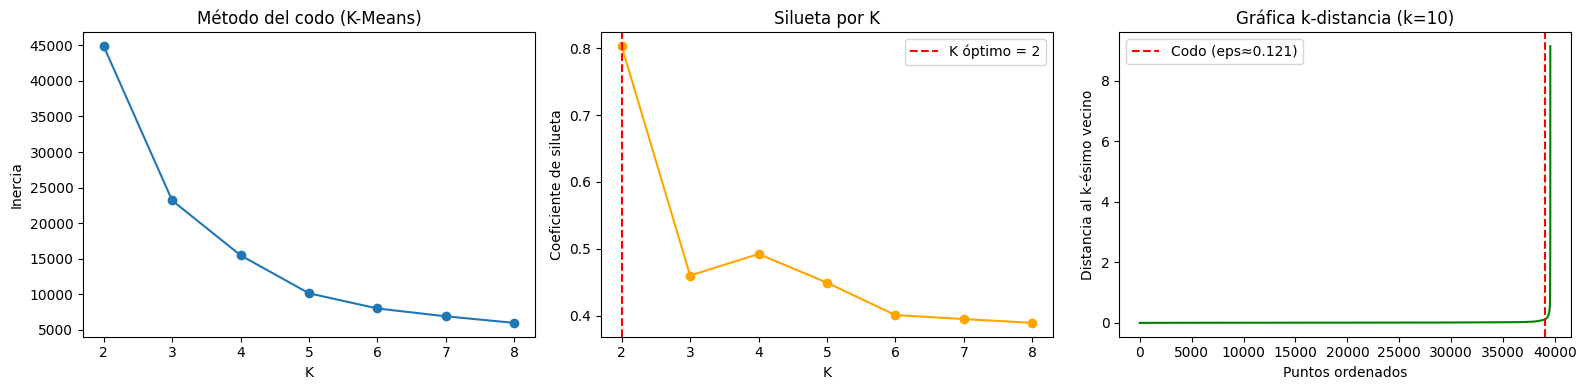

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_title("Método del codo (K-Means)")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inercia")

axes[1].plot(list(ks), silhouettes, marker="o", color="orange")
axes[1].axvline(k_optimo, color="red", linestyle="--", label=f"K óptimo = {k_optimo}")
axes[1].set_title("Silueta por K")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].legend()

axes[2].plot(k_distancias, color="green")
axes[2].axvline(idx_codo, color="red", linestyle="--", label=f"Codo (eps≈{eps_sugerido:.3f})")
axes[2].set_title(f"Gráfica k-distancia (k={k_vecinos})")
axes[2].set_xlabel("Puntos ordenados")
axes[2].set_ylabel("Distancia al k-ésimo vecino")
axes[2].legend()

plt.tight_layout()
plt.show()


## 3. Rol 3 — Modelador de Mezclas y Variables Latentes

Modelo de Mezclas Gaussianas (GMM) sobre distancia, duración y hora (cíclica), comparando inicialización aleatoria vs k-means++.

In [15]:
# Features para los perfiles de viaje: distancia y duración (y hora, cíclica)
df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)
X_perfil = df[["distancia_km", "trip_duration", "hora_sin", "hora_cos"]].values
X_perfil_norm = (X_perfil - X_perfil.mean(axis=0)) / X_perfil.std(axis=0)

N_COMPONENTES = 3  # commuter corto / aeropuerto-largo / nocturno-medio (hipótesis de negocio)

gmm_random = GaussianMixture(
    n_components=N_COMPONENTES, init_params="random",
    random_state=RANDOM_STATE, max_iter=200
).fit(X_perfil_norm)

gmm_kmeanspp = GaussianMixture(
    n_components=N_COMPONENTES, init_params="k-means++",
    random_state=RANDOM_STATE, max_iter=200
).fit(X_perfil_norm)

print(f"Init aleatoria : convergió={gmm_random.converged_}, iteraciones={gmm_random.n_iter_}, log-verosimilitud={gmm_random.lower_bound_:.4f}")
print(f"Init k-means++ : convergió={gmm_kmeanspp.converged_}, iteraciones={gmm_kmeanspp.n_iter_}, log-verosimilitud={gmm_kmeanspp.lower_bound_:.4f}")


Init aleatoria : convergió=True, iteraciones=26, log-verosimilitud=-4.1487
Init k-means++ : convergió=True, iteraciones=19, log-verosimilitud=-3.9377


In [16]:
responsabilidades = gmm_kmeanspp.predict_proba(X_perfil_norm)
asignacion_dura = responsabilidades.argmax(axis=1)
duraciones_por_perfil = df.groupby(asignacion_dura)["trip_duration"].mean().round(0)
distancias_por_perfil = df.groupby(asignacion_dura)["distancia_km"].mean().round(2)
print("Perfiles latentes encontrados (duración media seg / distancia media km):")
for c in range(N_COMPONENTES):
    print(f"  Perfil {c}: dur≈{duraciones_por_perfil.get(c, float('nan'))}s, dist≈{distancias_por_perfil.get(c, float('nan'))}km, "
          f"peso π={gmm_kmeanspp.weights_[c]:.3f}")

resultados_rol3 = {
    "iter_random": gmm_random.n_iter_,
    "iter_kmeanspp": gmm_kmeanspp.n_iter_,
    "loglik_random": gmm_random.lower_bound_,
    "loglik_kmeanspp": gmm_kmeanspp.lower_bound_,
    "pesos_perfiles": gmm_kmeanspp.weights_.tolist(),
}
resultados_rol3


Perfiles latentes encontrados (duración media seg / distancia media km):
  Perfil 0: dur≈617.0s, dist≈1.79km, peso π=0.372
  Perfil 1: dur≈613.0s, dist≈2.14km, peso π=0.335
  Perfil 2: dur≈1441.0s, dist≈7.45km, peso π=0.293


{'iter_random': 26,
 'iter_kmeanspp': 19,
 'loglik_random': np.float64(-4.14867569173586),
 'loglik_kmeanspp': np.float64(-3.9376864142579464),
 'pesos_perfiles': [0.3719052800234111,
  0.33529303725680937,
  0.29280168271977935]}

## 4. Rol 4 — Insumos cuantitativos para las recomendaciones de negocio

In [17]:
top_zona_pico = df_pico["zona_grid"].value_counts(normalize=True).head(4)
print(f"Top zonas en hora pico (concentran {top_zona_pico.sum()*100:.0f}% de la demanda de esa franja):")
top_zona_pico


Top zonas en hora pico (concentran 94% de la demanda de esa franja):


zona_grid
4_2    0.704933
4_1    0.116069
3_1    0.081490
3_2    0.035342
Name: proportion, dtype: float64

## Resumen final — listo para copiar al documento/diapositivas/guion

In [18]:
print(">>> Resumen de resultados (para copiar al documento/diapositivas):")
print("Rol 1:", resultados_rol1)
print("Rol 2:", resultados_rol2)
print("Rol 3:", resultados_rol3)


>>> Resumen de resultados (para copiar al documento/diapositivas):
Rol 1: {'H_zona_pico': np.float64(1.5701405178572694), 'H_zona_valle': np.float64(1.7954039632905896), 'KL_laboral_vs_finde': np.float64(0.03205575695242253), 'MI_hora_zona_destino': np.float64(0.026651710042722206)}
Rol 2: {'k_optimo': 2, 'silueta_kmeans': 0.8033400776757963, 'davies_bouldin_kmeans': 0.17978143684024686, 'eps_dbscan': np.float64(0.1207094146050535), 'n_clusters_dbscan': 12, 'pct_ruido_dbscan': 0.8801213960546282, 'silueta_dbscan': 0.09646236187030342}
Rol 3: {'iter_random': 26, 'iter_kmeanspp': 19, 'loglik_random': np.float64(-4.14867569173586), 'loglik_kmeanspp': np.float64(-3.9376864142579464), 'pesos_perfiles': [0.3719052800234111, 0.33529303725680937, 0.29280168271977935]}
